# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Sandeep Reddy Banda
**Course:** MSCS-634 – Advanced Big Data and Data Mining
**Lab Assignment:** Lab 4 – Regression Analysis with Regularization Techniques

## Introduction

In this lab I work with the Diabetes dataset from scikit-learn and try out a few regression techniques on it: simple linear, multiple, polynomial, Ridge, and Lasso. For every model I check MAE, MSE, RMSE and R², and I make plots so I can actually see how each model behaves. The main thing I want to understand is how regularization helps when a model gets too complex.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (7, 5)
RANDOM_STATE = 42

## Step 1: Data Preparation

In [2]:
# Load the diabetes dataset as a dataframe
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
X = diabetes.data
y = diabetes.target

print("Shape of the data:", df.shape)
df.head()

Shape of the data: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Feature names, and what each one means
print("Features:", list(X.columns))
print()
print(diabetes.DESCR[:1800])

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6    

In [4]:
# Basic statistics and a missing value check
print(df.describe().round(3))
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

           age      sex      bmi       bp       s1       s2       s3       s4  \
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000   
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000   
std      0.048    0.048    0.048    0.048    0.048    0.048    0.048    0.048   
min     -0.107   -0.045   -0.090   -0.112   -0.127   -0.116   -0.102   -0.076   
25%     -0.037   -0.045   -0.034   -0.037   -0.034   -0.030   -0.035   -0.039   
50%      0.005   -0.045   -0.007   -0.006   -0.004   -0.004   -0.007   -0.003   
75%      0.038    0.051    0.031    0.036    0.028    0.030    0.029    0.034   
max      0.111    0.051    0.171    0.132    0.154    0.199    0.181    0.185   

            s5       s6   target  
count  442.000  442.000  442.000  
mean     0.000    0.000  152.133  
std      0.048    0.048   77.093  
min     -0.126   -0.138   25.000  
25%     -0.033   -0.033   87.000  
50%     -0.002   -0.001  140.500  
75%      0.032    0.028  

The dataset has 442 rows, 10 features and one target (`target`, a measure of disease progression after one year). There are no missing values and no duplicates, so no cleaning was needed. One thing I noticed is that the features are already mean-centered and scaled by sklearn, so they look like small decimals (for example `bmi` between about -0.09 and 0.17) and not real units like kg/m².

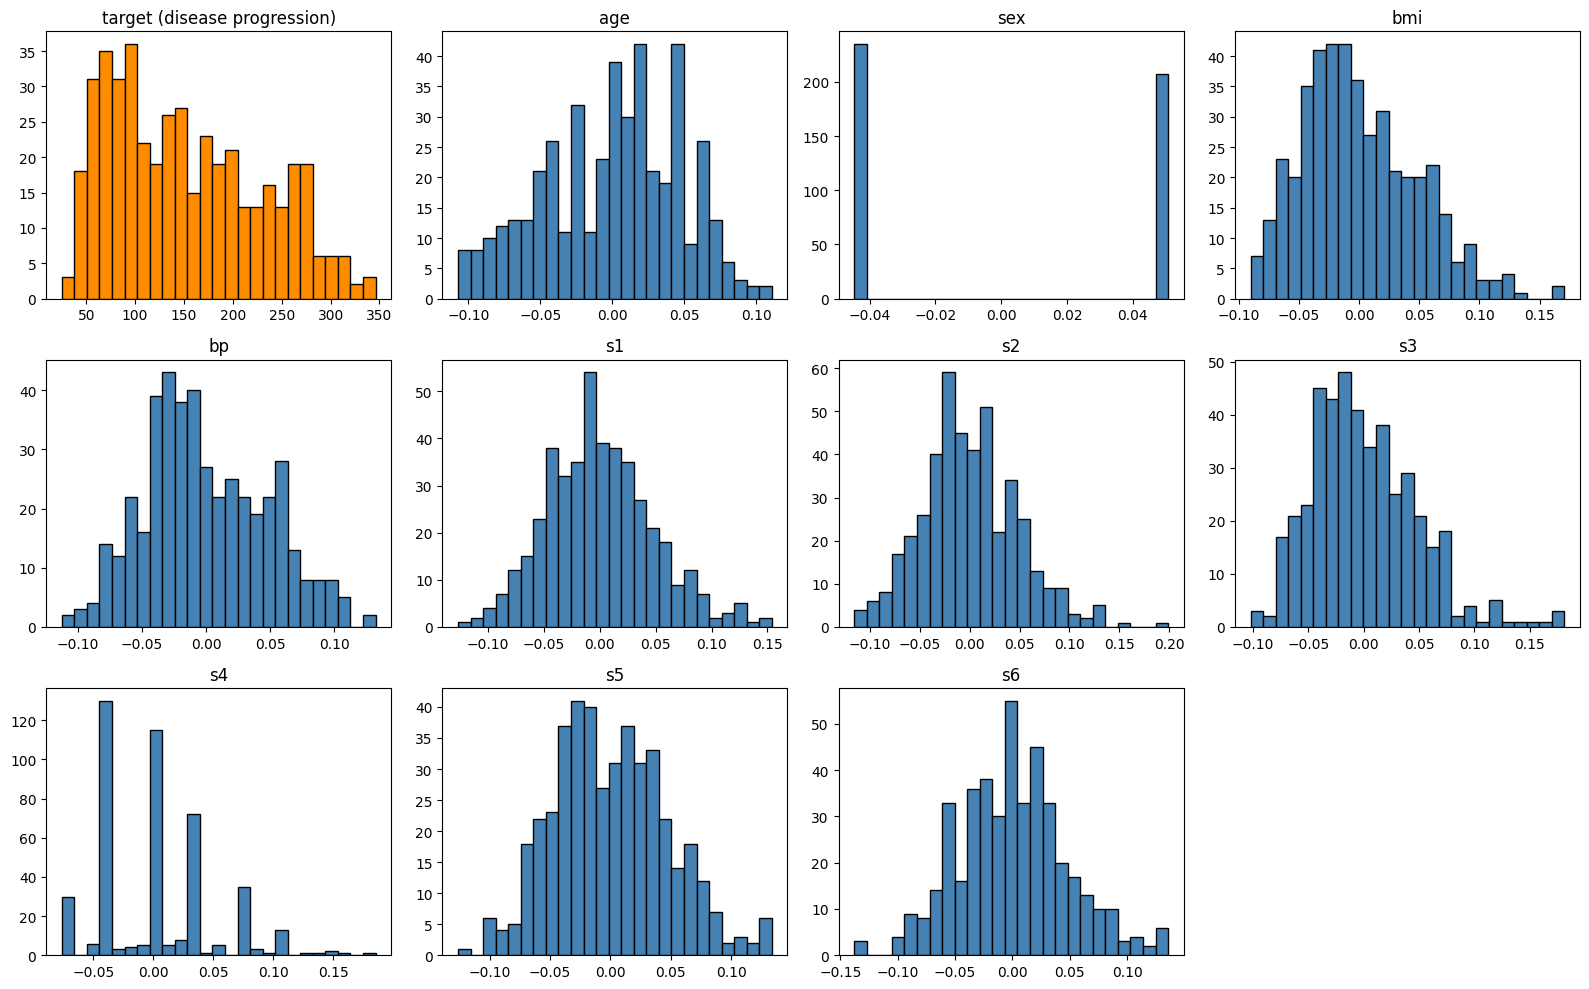

In [5]:
# Distribution of the target and of every feature
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
axes[0].hist(y, bins=25, color="darkorange", edgecolor="black")
axes[0].set_title("target (disease progression)")
for i, col in enumerate(X.columns):
    axes[i + 1].hist(X[col], bins=25, color="steelblue", edgecolor="black")
    axes[i + 1].set_title(col)
axes[11].axis("off")
plt.tight_layout()
plt.show()

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


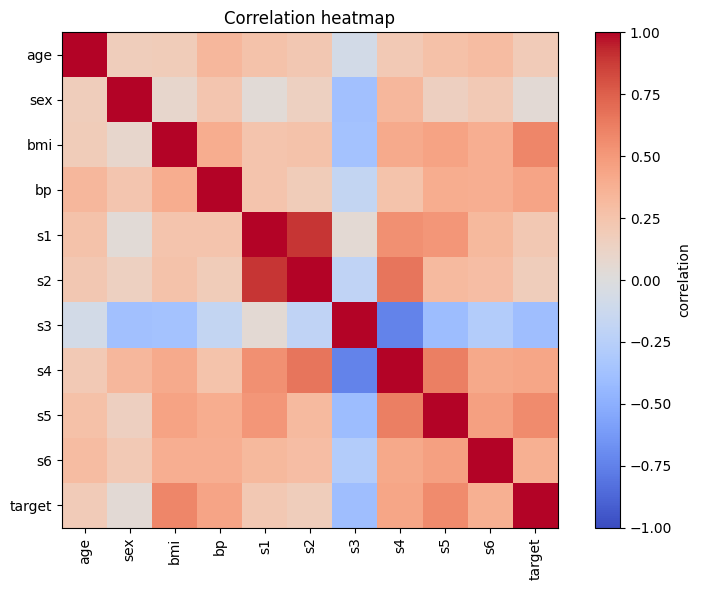

In [6]:
# Correlation of each feature with the target, plus a correlation heatmap
corr = df.corr()
print(corr["target"].drop("target").sort_values(ascending=False).round(3))

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

`bmi` and `s5` (a blood serum measurement) have the strongest correlation with the target, so `bmi` is a good pick for the simple linear regression. I also see that `s1` and `s2` are very strongly correlated with each other (and `s3` and `s4` are tied to them too). That is multicollinearity, and it should matter later when I get to Ridge and Lasso.

In [7]:
# Train / test split used for every model (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Helper to calculate the four metrics and keep a record of every model
results = []

def evaluate(name, y_true, y_pred, split="Test"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "Split": split, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

def report(name, model, Xtr, Xte):
    tr = evaluate(name, y_train, model.predict(Xtr), "Train")
    te = evaluate(name, y_test, model.predict(Xte), "Test")
    results.extend([tr, te])
    print(pd.DataFrame([tr, te]).set_index("Split").drop(columns="Model").round(3))

Train: (353, 10)  Test: (89, 10)


## Step 2: Simple Linear Regression

In [8]:
# Using only bmi (the feature most correlated with the target)
feature = "bmi"
Xtr_1 = X_train[[feature]]
Xte_1 = X_test[[feature]]

lin = LinearRegression()
lin.fit(Xtr_1, y_train)

print("Intercept:", round(lin.intercept_, 2), " Slope:", round(lin.coef_[0], 2))
report("Simple Linear (bmi)", lin, Xtr_1, Xte_1)

Intercept: 152.0  Slope: 998.58
         MAE       MSE    RMSE     R2
Split                                
Train  51.38  3854.113  62.082  0.366
Test   52.26  4061.826  63.732  0.233


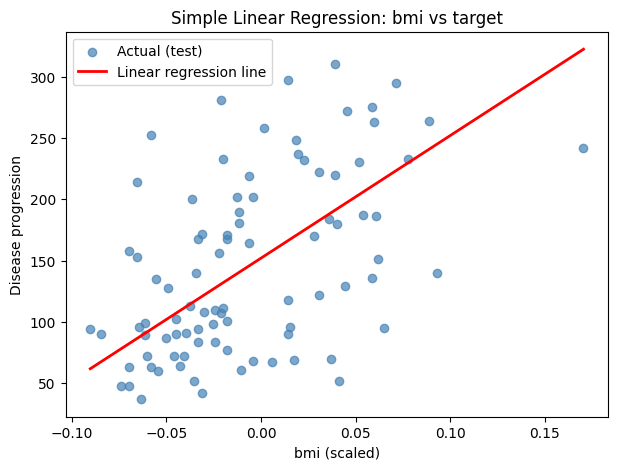

In [9]:
# Plot: actual test data vs the fitted line
x_line = np.linspace(X[feature].min(), X[feature].max(), 100).reshape(-1, 1)
plt.scatter(Xte_1, y_test, color="steelblue", alpha=0.7, label="Actual (test)")
plt.plot(x_line, lin.predict(pd.DataFrame(x_line, columns=[feature])),
         color="red", linewidth=2, label="Linear regression line")
plt.xlabel("bmi (scaled)")
plt.ylabel("Disease progression")
plt.title("Simple Linear Regression: bmi vs target")
plt.legend()
plt.show()

**Observation:** A single feature explains only part of the variation in the target. The points are spread out a lot around the line, so one feature is not enough to predict disease progression well.

## Step 3: Multiple Regression

In [10]:
multi = LinearRegression()
multi.fit(X_train, y_train)

report("Multiple Linear (all 10)", multi, X_train, X_test)

print()
print(pd.Series(multi.coef_, index=X.columns).round(1))

          MAE       MSE    RMSE     R2
Split                                 
Train  43.484  2868.550  53.559  0.528
Test   42.794  2900.194  53.853  0.453

age     37.9
sex   -242.0
bmi    542.4
bp     347.7
s1    -931.5
s2     518.1
s3     163.4
s4     275.3
s5     736.2
s6      48.7
dtype: float64


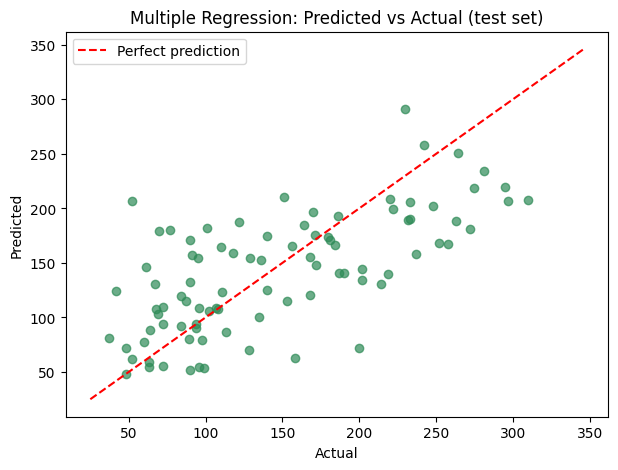

In [11]:
# Predicted vs actual for the multiple regression model
pred_multi = multi.predict(X_test)
plt.scatter(y_test, pred_multi, color="seagreen", alpha=0.7)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Multiple Regression: Predicted vs Actual (test set)")
plt.legend()
plt.show()

**Observation:** Using all 10 features gives a clear improvement over the simple model. The points are closer to the dashed line, but there is still a lot of scatter, so the model is far from perfect. The coefficients of `s1` and `s2` are large and have opposite signs, which is a typical sign of multicollinearity.

## Step 4: Polynomial Regression

In [12]:
# Polynomial regression on all features, degrees 1 to 4
poly_rows = []
for d in [1, 2, 3, 4]:
    pipe = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), LinearRegression())
    pipe.fit(X_train, y_train)
    n_feat = pipe.named_steps["polynomialfeatures"].n_output_features_
    tr = evaluate(f"Poly deg {d}", y_train, pipe.predict(X_train), "Train")
    te = evaluate(f"Poly deg {d}", y_test, pipe.predict(X_test), "Test")
    poly_rows.append({"Degree": d, "Num features": n_feat,
                      "Train R2": tr["R2"], "Test R2": te["R2"],
                      "Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"]})
    if d in (2, 3):   # keep these two for the final comparison
        results.extend([tr, te])

poly_df = pd.DataFrame(poly_rows).round(3)
poly_df

,Degree,Num features,Train R2,Test R2,Train RMSE,Test RMSE
0,1,10,0.528,0.453,53.559,53.853
1,2,65,0.606,0.416,48.920,55.642
2,3,285,0.877,-14.561,27.306,287.134
3,4,1000,1.000,-26.728,0.000,383.285


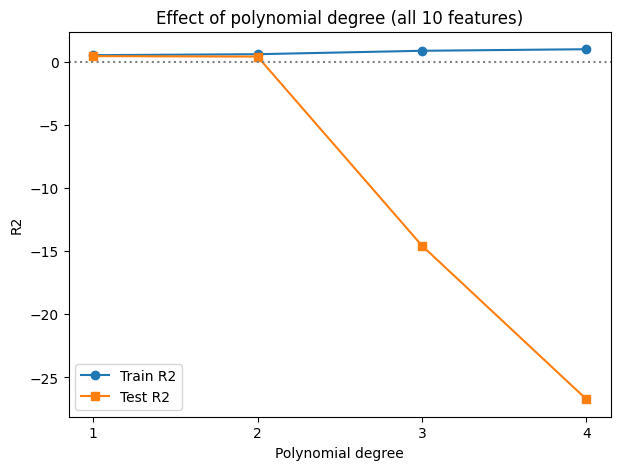

In [13]:
# Train vs test R2 as the degree increases
plt.plot(poly_df["Degree"], poly_df["Train R2"], "o-", label="Train R2")
plt.plot(poly_df["Degree"], poly_df["Test R2"], "s-", label="Test R2")
plt.axhline(0, color="gray", linestyle=":")
plt.xticks([1, 2, 3, 4])
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Effect of polynomial degree (all 10 features)")
plt.legend()
plt.show()

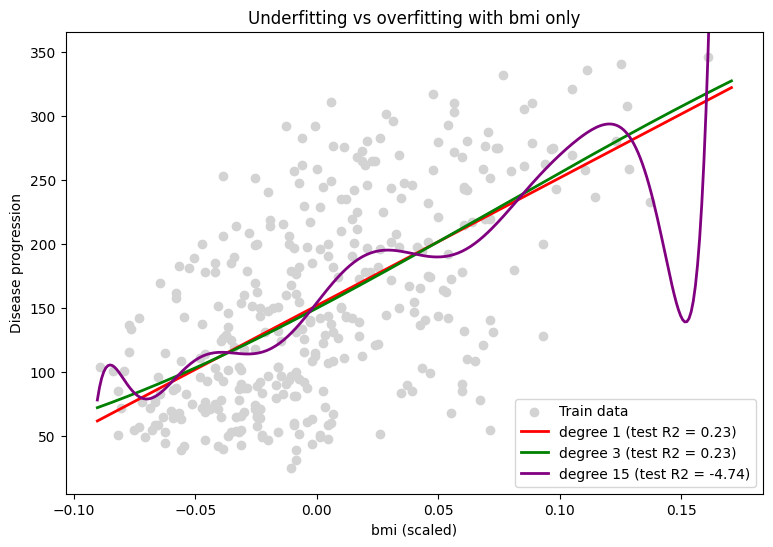

In [14]:
# A visual of under/overfitting with a single feature (bmi) so the curves can be drawn
x_line = pd.DataFrame(np.linspace(X["bmi"].min(), X["bmi"].max(), 300), columns=["bmi"])
plt.figure(figsize=(9, 6))
plt.scatter(X_train["bmi"], y_train, color="lightgray", label="Train data")
for d, c in [(1, "red"), (3, "green"), (15, "purple")]:
    p = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), LinearRegression())
    p.fit(X_train[["bmi"]], y_train)
    test_r2 = r2_score(y_test, p.predict(X_test[["bmi"]]))
    plt.plot(x_line, p.predict(x_line), color=c, linewidth=2,
             label=f"degree {d} (test R2 = {test_r2:.2f})")
plt.ylim(y.min() - 20, y.max() + 20)
plt.xlabel("bmi (scaled)")
plt.ylabel("Disease progression")
plt.title("Underfitting vs overfitting with bmi only")
plt.legend()
plt.show()

**Observation:** Polynomial regression is a good example of how a model can get too flexible.

- **Degree 1** is just the multiple regression model (test R² = 0.453).
- **Degree 2** (65 features) fits the training data better (train R² 0.606) but the test R² actually drops a bit to 0.416. It is already starting to overfit.
- **Degree 3** (285 features) is a big overfit. Train R² is 0.877 but test R² is **-14.56**, which means it predicts much worse than just guessing the average.
- **Degree 4** (1000 features) has more features than the 353 training rows, so it memorizes the training data perfectly (train R² = 1.0), and the test R² is -26.7.

The single-feature plot shows the other side of it. The degree 1 line is too simple to follow the data (underfitting), and the degree 15 curve twists around to chase individual points (overfitting). Degree 3 is somewhere in the middle. So the gap between train and test scores is the clearest sign of overfitting here.

## Step 5: Regularization with Ridge and Lasso

Since polynomial features make the model much more complex (degree 2 gives 65 features), this is a good place to use regularization. I use degree 2 polynomial features, standardize them (regularization is sensitive to feature scale), and then fit Ridge and Lasso. I first try a range of alpha values and then pick the best alpha with 5-fold cross-validation on the **training** set only, so the test set stays untouched.

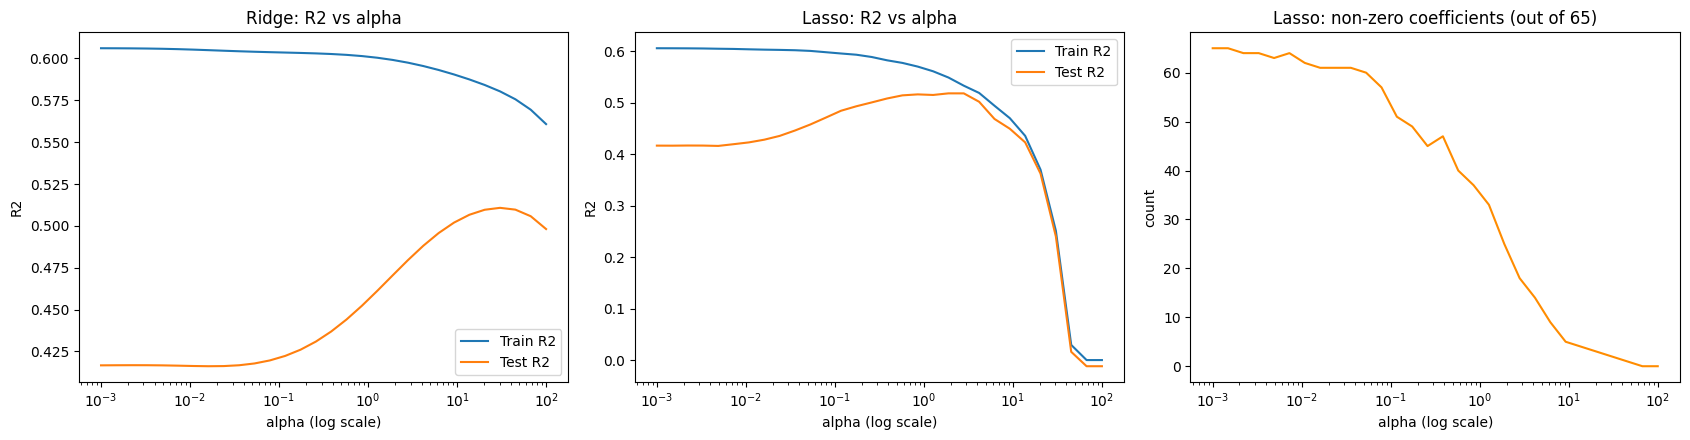

In [15]:
alphas = np.logspace(-3, 2, 30)
ridge_train, ridge_test, lasso_train, lasso_test, lasso_nonzero = [], [], [], [], []

def poly_model(est):
    return make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                         StandardScaler(), est)

for a in alphas:
    r = poly_model(Ridge(alpha=a)).fit(X_train, y_train)
    l = poly_model(Lasso(alpha=a, max_iter=50000)).fit(X_train, y_train)
    ridge_train.append(r2_score(y_train, r.predict(X_train)))
    ridge_test.append(r2_score(y_test, r.predict(X_test)))
    lasso_train.append(r2_score(y_train, l.predict(X_train)))
    lasso_test.append(r2_score(y_test, l.predict(X_test)))
    lasso_nonzero.append(int(np.sum(l[-1].coef_ != 0)))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].semilogx(alphas, ridge_train, label="Train R2")
axes[0].semilogx(alphas, ridge_test, label="Test R2")
axes[0].set_title("Ridge: R2 vs alpha")
axes[1].semilogx(alphas, lasso_train, label="Train R2")
axes[1].semilogx(alphas, lasso_test, label="Test R2")
axes[1].set_title("Lasso: R2 vs alpha")
for ax in axes[:2]:
    ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("R2"); ax.legend()
axes[2].semilogx(alphas, lasso_nonzero, color="darkorange")
axes[2].set_title("Lasso: non-zero coefficients (out of 65)")
axes[2].set_xlabel("alpha (log scale)"); axes[2].set_ylabel("count")
plt.tight_layout()
plt.show()

In [16]:
# Pick the best alpha for each using cross-validation on the training set
grid = {"ridge__alpha": np.logspace(-2, 3, 40)}
ridge_gs = GridSearchCV(
    make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), Ridge()),
    {"ridge__alpha": np.logspace(-2, 3, 40)}, cv=5, scoring="neg_mean_squared_error")
lasso_gs = GridSearchCV(
    make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), Lasso(max_iter=50000)),
    {"lasso__alpha": np.logspace(-3, 1, 40)}, cv=5, scoring="neg_mean_squared_error")
ridge_gs.fit(X_train, y_train)
lasso_gs.fit(X_train, y_train)

best_ridge = ridge_gs.best_estimator_
best_lasso = lasso_gs.best_estimator_
print("Best Ridge alpha:", round(ridge_gs.best_params_["ridge__alpha"], 3))
print("Best Lasso alpha:", round(lasso_gs.best_params_["lasso__alpha"], 4))
print("Lasso kept", int(np.sum(best_lasso[-1].coef_ != 0)), "of", len(best_lasso[-1].coef_), "polynomial features")
print()
print("--- Ridge (degree 2) ---")
report("Ridge (poly deg 2)", best_ridge, X_train, X_test)
print()
print("--- Lasso (degree 2) ---")
report("Lasso (poly deg 2)", best_lasso, X_train, X_test)

Best Ridge alpha: 94.267
Best Lasso alpha: 3.8882
Lasso kept 14 of 65 polynomial features

--- Ridge (degree 2) ---
          MAE       MSE    RMSE     R2
Split                                 
Train  41.841  2659.919  51.574  0.562
Test   41.449  2651.646  51.494  0.500

--- Lasso (degree 2) ---
          MAE       MSE    RMSE     R2
Split                                 
Train  44.205  2904.041  53.889  0.522
Test   41.803  2615.287  51.140  0.506


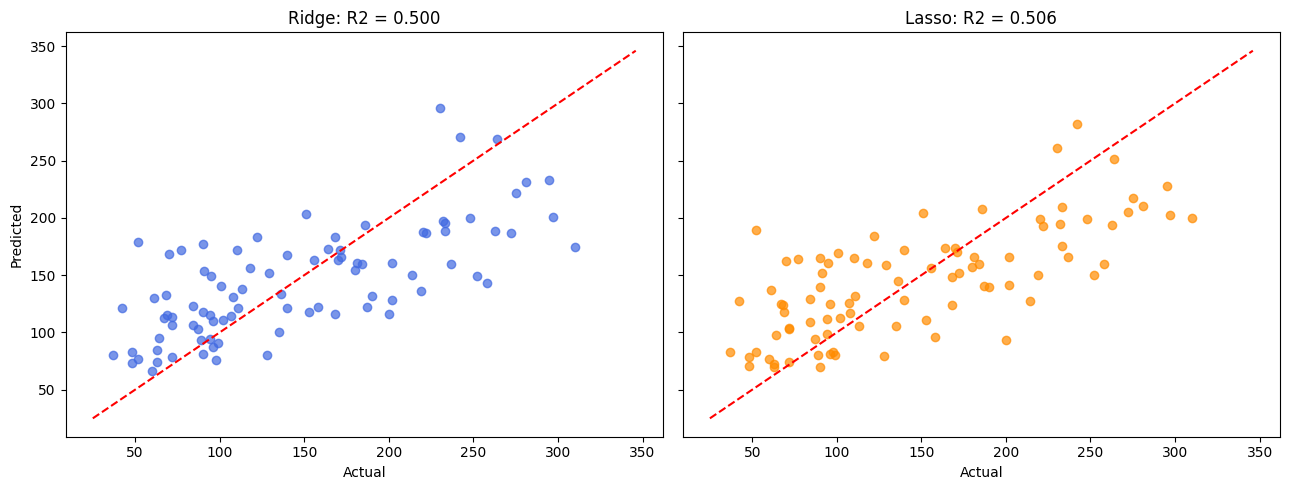

In [17]:
# Predicted vs actual: Ridge vs Lasso side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, model, name, color in [(axes[0], best_ridge, "Ridge", "royalblue"),
                               (axes[1], best_lasso, "Lasso", "darkorange")]:
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.7, color=color)
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name}: R2 = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
plt.tight_layout()
plt.show()

     Linear  Ridge (alpha=10)  Lasso (alpha=1)
age    1.75              1.93             0.69
sex  -11.51            -11.03            -9.30
bmi   25.61             25.61            26.22
bp    16.83             16.30            15.66
s1   -44.45            -12.93            -8.23
s2    24.64              0.54            -0.00
s3     7.68             -6.13            -9.02
s4    13.14              8.57             3.42
s5    35.16             22.75            22.64
s6     2.35              2.92             2.10


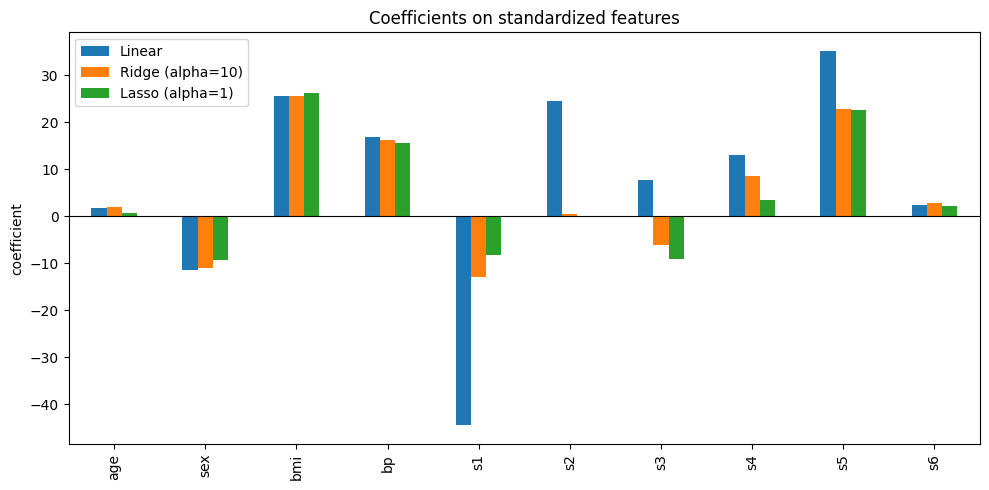

In [18]:
# Ridge and Lasso on the original 10 features, to see what they do to the coefficients
ridge10 = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train, y_train)
lasso10 = make_pipeline(StandardScaler(), Lasso(alpha=1.0)).fit(X_train, y_train)
ols10 = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)

coef_df = pd.DataFrame({
    "Linear": ols10[-1].coef_,
    "Ridge (alpha=10)": ridge10[-1].coef_,
    "Lasso (alpha=1)": lasso10[-1].coef_}, index=X.columns)
print(coef_df.round(2))

coef_df.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Coefficients on standardized features")
plt.ylabel("coefficient")
plt.tight_layout()
plt.show()

**Observation (how alpha changes the model):**

- **Ridge** shrinks all the coefficients toward zero but never makes them exactly zero. When alpha is very small, Ridge behaves like plain polynomial regression and the test R² is poor. As alpha grows, the training R² goes down slowly while the test R² improves, until the best alpha (about 94 from cross-validation). If alpha is too large the model gets too simple and underfits.
- **Lasso** also shrinks coefficients, but it pushes some of them to exactly zero, so it works as feature selection. With the cross-validated alpha (about 3.9) it kept only **14 of the 65** polynomial features. The third plot shows the number of non-zero coefficients dropping as alpha increases.
- On the original 10 features, plain linear regression gave `s1` and `s2` huge opposite coefficients (-44 and +25). Ridge pulled them back (-13 and 0.5), and Lasso dropped `s2` to exactly 0. This matches the multicollinearity I saw in the heatmap.
- Both models fixed the overfitting of the degree 2 polynomial model: test R² went from 0.416 to 0.500 (Ridge) and 0.506 (Lasso). Their train and test scores are also much closer together. Ridge had slightly better training scores, while Lasso had slightly better test scores and a simpler model, but the difference between them is small.

## Step 6: Model Comparison and Analysis

In [19]:
results_df = pd.DataFrame(results)
test_df = results_df[results_df["Split"] == "Test"].drop(columns="Split").set_index("Model")
train_df = results_df[results_df["Split"] == "Train"].drop(columns="Split").set_index("Model")

print("TEST SET")
print(test_df.round(3))
print()
print("TRAIN SET")
print(train_df.round(3))

TEST SET
                              MAE        MSE     RMSE      R2
Model                                                        
Simple Linear (bmi)        52.260   4061.826   63.732   0.233
Multiple Linear (all 10)   42.794   2900.194   53.853   0.453
Poly deg 2                 43.582   3096.028   55.642   0.416
Poly deg 3                164.854  82446.048  287.134 -14.561
Ridge (poly deg 2)         41.449   2651.646   51.494   0.500
Lasso (poly deg 2)         41.803   2615.287   51.140   0.506

TRAIN SET
                             MAE       MSE    RMSE     R2
Model                                                    
Simple Linear (bmi)       51.380  3854.113  62.082  0.366
Multiple Linear (all 10)  43.484  2868.550  53.559  0.528
Poly deg 2                39.143  2393.139  48.920  0.606
Poly deg 3                18.689   745.618  27.306  0.877
Ridge (poly deg 2)        41.841  2659.919  51.574  0.562
Lasso (poly deg 2)        44.205  2904.041  53.889  0.522


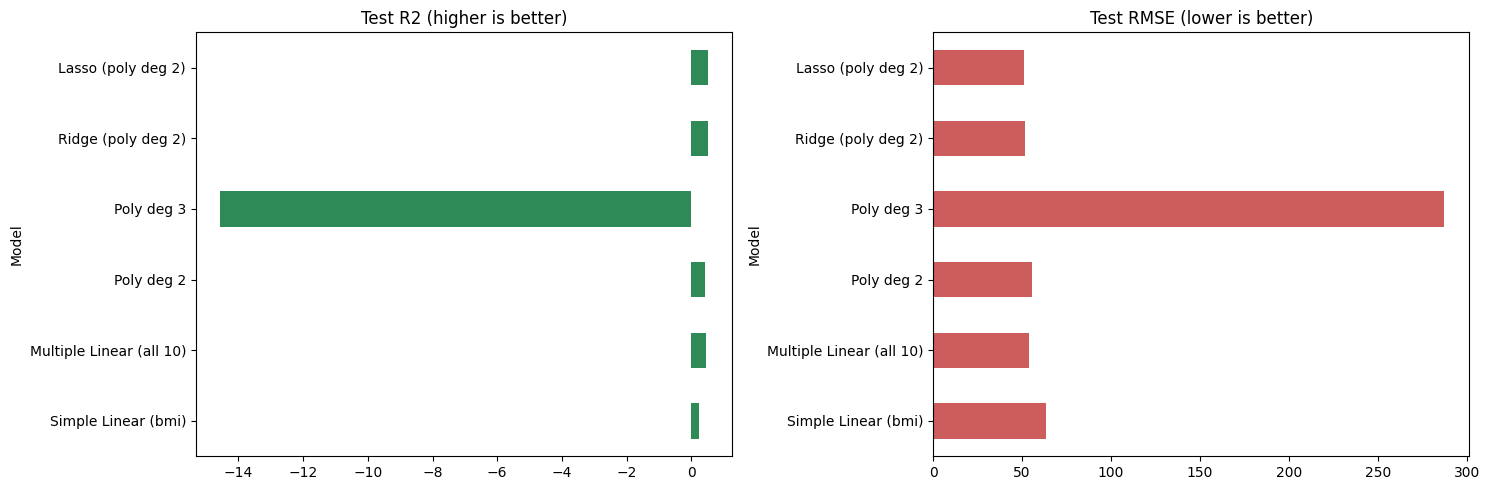

In [20]:
# Bar charts: test R2 and test RMSE for every model
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
test_df["R2"].plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Test R2 (higher is better)")
test_df["RMSE"].plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Test RMSE (lower is better)")
plt.tight_layout()
plt.show()

### Summary of results

| Model | Test R² | Test RMSE | Test MAE |
|---|---|---|---|
| Simple Linear (bmi) | 0.233 | 63.73 | 52.26 |
| Multiple Linear (all 10) | 0.453 | 53.85 | 42.79 |
| Polynomial degree 2 | 0.416 | 55.64 | 43.58 |
| Polynomial degree 3 | -14.561 | 287.13 | 164.85 |
| Ridge (poly degree 2) | 0.500 | 51.49 | 41.45 |
| **Lasso (poly degree 2)** | **0.506** | **51.14** | 41.80 |

### Key observations

**How well each model performed.** The simple linear model with just `bmi` was the weakest of the reasonable models (R² = 0.23), so one feature cannot explain disease progression. Adding all 10 features raised R² to 0.45. The polynomial models did not help without regularization: degree 2 was slightly worse on the test set than the multiple regression, and degree 3 completely broke down.

**Which models handled overfitting.** Ridge and Lasso both did. They used the same degree 2 features that overfit on their own and got the best test results (R² of about 0.50 and RMSE of about 51). Lasso was a little better on the test set and also used only 14 features, so I would call it the best model overall. The difference between Ridge and Lasso is small, though, and it could change with a different random split, so I would not say one is clearly better.

**Insights about the Diabetes dataset.**
- `bmi` and `s5` are the strongest predictors, and `bp` is next. These features stayed important even after regularization.
- `s1` and `s2` are highly correlated with each other, which makes the plain linear coefficients unstable. Regularization handled this well.
- The dataset is small (442 rows), so complex models overfit very quickly.
- Even the best model only explains about 50% of the variance, so the 10 features alone are not enough for an accurate prediction, and the relationship is not strongly non-linear.

### Challenges and decisions
- I used an 80/20 split with `random_state=42` for every model so the comparison is fair.
- I standardized the features before Ridge and Lasso since the penalty depends on feature scale.
- I chose alpha with cross-validation on the training set only, so the test set was not used for tuning.
- I used degree 2 for regularization because degree 3 and above have too many features for 353 training rows.